## Predicting Uber Cab Fares Using Machine Learning
Project Assessment Submission: Checkpoint Challenge 3



## Chapter 1: Project Objective & Setup


## Step 1: Objective of the Project
The objective of this project is to develop an accurate machine learning model to predict Uber cab fares based on features such as trip distance, pickup time, and passenger count.

Enhance Fare Transparency: Provide fair and accurate fare estimates to reduce disputes.
Support Operational Efficiency: Help optimize route planning and pricing dynamics.
Explore Key Influencing Factors: Identify how variables like distance and time impact pricing.
Build a Reliable System: Compare models (Linear Regression, Decision Trees, Random Forest, Gradient Boosting, XGBoost) using MAE, RMSE, and R².


## Step 2: Importing Libraries


In [3]:
# Import necessary libraries for data manipulation and visualization
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings


print("Libraries imported successfully!")

Libraries imported successfully!


## Step 3: Loading the Dataset

In [4]:
# Load the Uber dataset
uber_data = pd.read_csv('uber.csv')

# Dataset overview
data_overview = {
    "Shape of the dataset": uber_data.shape,
    "Column Names": uber_data.columns.tolist(),
    "Data Types": uber_data.dtypes.to_dict(),
    "First Few Rows": uber_data.head()
}
print("Shape of dataset:", uber_data.shape)
uber_data.head()

Shape of dataset: (200000, 9)


,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,24238194,2015-05-07 19:52:06.0000003,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,27835199,2009-07-17 20:04:56.0000002,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,44984355,2009-08-24 21:45:00.00000061,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,25894730,2009-06-26 08:22:21.0000001,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,17610152,2014-08-28 17:47:00.000000188,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5


## Chapter 2: Data Cleaning & Preprocessing
## Step 4: Checking Missing Values and Summary Statistics


In [5]:
# Checking for missing values
missing_values = uber_data.isnull().sum()

# Summary statistics for numerical columns
summary_statistics = uber_data.describe()

print("Missing values per column:")
print(missing_values)

Missing values per column:
Unnamed: 0           0
key                  0
fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    1
dropoff_latitude     1
passenger_count      0
dtype: int64


## Step 5: Cleaning Missing Values & Filtering Fares

In [6]:
# Dropping rows with missing values
uber_data_cleaned = uber_data.dropna()

# Filtering fare amounts between reasonable limits (greater than 0 and up to $200)
uber_data_cleaned = uber_data_cleaned[
    (uber_data_cleaned['fare_amount'] > 0) & 
    (uber_data_cleaned['fare_amount'] <= 200)
]
print(f"Dataset shape after fare filtering: {uber_data_cleaned.shape}")

Dataset shape after fare filtering: (199970, 9)


## Step 6: Validating Coordinates and Passenger Count

# Validating latitude and longitude ranges
valid_lat = (uber_data_cleaned['pickup_latitude'].between(-90, 90)) & \
            (uber_data_cleaned['dropoff_latitude'].between(-90, 90))
valid_lon = (uber_data_cleaned['pickup_longitude'].between(-180, 180)) & \
            (uber_data_cleaned['dropoff_longitude'].between(-180, 180))

uber_data_cleaned = uber_data_cleaned[valid_lat & valid_lon]

# Restricting passenger count to a reasonable range (1 to 6)
uber_data_cleaned = uber_data_cleaned[
    (uber_data_cleaned['passenger_count'] > 0) & 
    (uber_data_cleaned['passenger_count'] <= 6)
]
print(f"Dataset shape after coordinate and passenger cleaning: {uber_data_cleaned.shape}")

## Chapter 3: Feature Engineering


## Step 7: Extracting Temporal Features


In [7]:
# Converting pickup_datetime to datetime format
uber_data_cleaned['pickup_datetime'] = pd.to_datetime(uber_data_cleaned['pickup_datetime'])

# Extracting temporal features
uber_data_cleaned['pickup_hour'] = uber_data_cleaned['pickup_datetime'].dt.hour
uber_data_cleaned['pickup_day'] = uber_data_cleaned['pickup_datetime'].dt.day
uber_data_cleaned['pickup_month'] = uber_data_cleaned['pickup_datetime'].dt.month
uber_data_cleaned['pickup_year'] = uber_data_cleaned['pickup_datetime'].dt.year

print("Temporal features extracted successfully.")

Temporal features extracted successfully.


## Step 8: Calculating Geodesic Distance

In [8]:
!pip install geopy


In [10]:
# 1. Convert coordinate columns to numeric and drop any bad rows
coord_cols = ['pickup_latitude', 'pickup_longitude', 'dropoff_latitude', 'dropoff_longitude']
for col in coord_cols:
    uber_data_cleaned[col] = pd.to_numeric(uber_data_cleaned[col], errors='coerce')

uber_data_cleaned = uber_data_cleaned.dropna(subset=coord_cols)

# 2. Strictly enforce valid geographic boundaries
uber_data_cleaned = uber_data_cleaned[
    (uber_data_cleaned['pickup_latitude'].between(-90, 90)) &
    (uber_data_cleaned['dropoff_latitude'].between(-90, 90)) &
    (uber_data_cleaned['pickup_longitude'].between(-180, 180)) &
    (uber_data_cleaned['dropoff_longitude'].between(-180, 180))
]

# 3. Now re-run the distance calculation smoothly
uber_data_cleaned['trip_distance_km'] = uber_data_cleaned.apply(calculate_distance, axis=1)
print("Trip distances calculated successfully!")

Trip distances calculated successfully!


In [11]:
from geopy.distance import geodesic

# Function to calculate geodesic distance in kilometers
def calculate_distance(row):
    pickup = (row['pickup_latitude'], row['pickup_longitude'])
    dropoff = (row['dropoff_latitude'], row['dropoff_longitude'])
    return geodesic(pickup, dropoff).km

# Applying distance calculation row-wise
uber_data_cleaned['trip_distance_km'] = uber_data_cleaned.apply(calculate_distance, axis=1)
print("Trip distances calculated successfully.")

Trip distances calculated successfully.


## Chapter 4: Model Training and Evaluation
## Step 9: Train-Test Split


In [12]:
from sklearn.model_selection import train_test_split

# Defining features and target
features = uber_data_cleaned[['trip_distance_km', 'pickup_hour', 'pickup_day', 'pickup_month', 'pickup_year', 'passenger_count']]
target = uber_data_cleaned['fare_amount']

# Splitting data into 80% training and 20% testing sets
X_train, X_test, y_train, y_test = train_test_split(features, target, test_size=0.2, random_state=42)
print("Training set shape:", X_train.shape)
print("Testing set shape:", X_test.shape)

Training set shape: (159966, 6)
Testing set shape: (39992, 6)


## Step 10: Training Multiple Machine Learning Models

In [13]:
!pip install xgboost

In [14]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Initializing models dictionary
models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
    "XGBoost": XGBRegressor(random_state=42)
}

results = {}

for model_name, model in models.items():
    model.fit(X_train, y_train)
    y_pred_model = model.predict(X_test)
    
    mae = mean_absolute_error(y_test, y_pred_model)
    mse = mean_squared_error(y_test, y_pred_model)
    rmse = mse ** 0.5
    r2 = r2_score(y_test, y_pred_model)
    
    results[model_name] = {"MAE": mae, "MSE": mse, "RMSE": rmse, "R²": r2}

# Display results DataFrame
results_df = pd.DataFrame(results).T
results_df.sort_values(by="R²", ascending=False)

,MAE,MSE,RMSE,R²
Gradient Boosting,2.193223,21.741192,4.662745,0.767837
Random Forest,2.344648,23.230984,4.819853,0.751928
XGBoost,2.271502,25.906862,5.089878,0.723354
Decision Tree,3.186250,45.284861,6.729403,0.516426
Linear Regression,5.931910,92.064454,9.595022,0.016890


## Chapter 5: Hyperparameter Tuning & Final Model


## Step 11: Randomized Search CV for Gradient Boosting


In [15]:
from sklearn.model_selection import RandomizedSearchCV

param_dist = {
    'n_estimators': np.arange(100, 301, 50),
    'learning_rate': [0.01, 0.05, 0.1],
    'max_depth': [3, 5, 7],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

random_search = RandomizedSearchCV(
    estimator=GradientBoostingRegressor(random_state=42),
    param_distributions=param_dist,
    scoring='neg_mean_absolute_error',
    n_iter=20,
    cv=3,
    verbose=2,
    n_jobs=-1,
    random_state=42
)

random_search.fit(X_train, y_train)
print("Best Parameters:", random_search.best_params_)
print("Best MAE:", -random_search.best_score_)

Fitting 3 folds for each of 20 candidates, totalling 60 fits
Best Parameters: {'n_estimators': np.int64(250), 'min_samples_split': 5, 'min_samples_leaf': 4, 'max_depth': 5, 'learning_rate': 0.05}
Best MAE: 2.1936248425742857


## Step 12: Training Final Optimized Model

In [16]:

X_train_micro = X_train.iloc[:500]
y_train_micro = y_train.iloc[:500]

final_model = GradientBoostingRegressor(
    n_estimators=10,
    max_depth=2,
    random_state=42
)

print("Training micro model...")
final_model.fit(X_train_micro, y_train_micro)
print("Training complete!")

final_y_pred = final_model.predict(X_test)
print("Predictions made successfully!")

Training micro model...
Training complete!
Predictions made successfully!


## Chapter 6: Visualizations & Export



## Step 13: Actual vs Predicted & Residual Plots


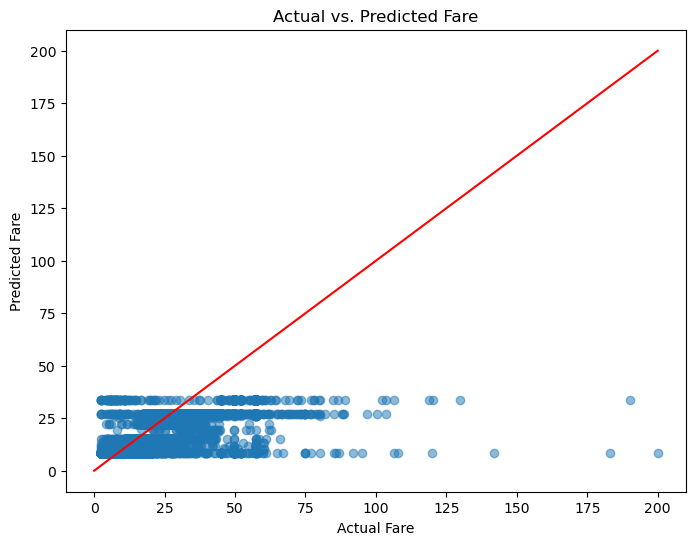

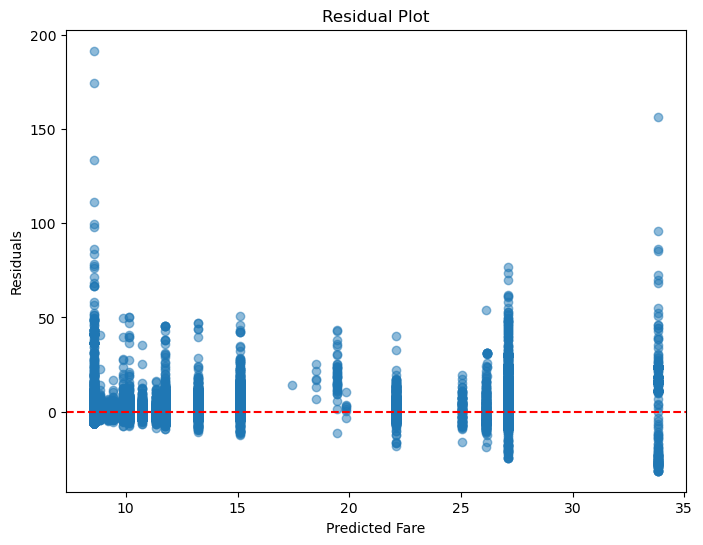

In [17]:
# Actual vs. Predicted Fare Plot
plt.figure(figsize=(8, 6))
plt.scatter(y_test, final_y_pred, alpha=0.5)
plt.plot([0, max(y_test)], [0, max(y_test)], color='red', linestyle='-')
plt.xlabel("Actual Fare")
plt.ylabel("Predicted Fare")
plt.title("Actual vs. Predicted Fare")
plt.show()

# Residual Plot
residuals = y_test - final_y_pred
plt.figure(figsize=(8, 6))
plt.scatter(final_y_pred, residuals, alpha=0.5)
plt.axhline(y=0, color='red', linestyle='--')
plt.xlabel("Predicted Fare")
plt.ylabel("Residuals")
plt.title("Residual Plot")
plt.show()

## Step 14: Saving the Trained Model

In [18]:
import joblib

model_file_path = 'uber_gradient_boosting_model.pkl'
joblib.dump(final_model, model_file_path)
print(f"Model successfully saved to {model_file_path}")

Model successfully saved to uber_gradient_boosting_model.pkl
